# BIOT 6900 · Module 10 — Medical Imaging AI
## Toy notebook: MedNIST, a CNN you can watch learn

*Week 10 · Part III · run-and-read (ungraded)*

This is the gentle on-ramp for the week. Before we touch real pathology — which is scarce, messy, and easy to fool — we build the whole pipeline once on data that is **plentiful and easy**, so every moving part is visible.

By the end you will have:

1. Loaded real medical images with **MONAI** and seen each preprocessing step explicitly.
2. Trained a small CNN **from scratch** and watched it reach high accuracy.
3. Run **Grad-CAM** — the one tool this whole module is about — where *"where did the model look?"* has an obvious right answer.
4. Deliberately **broken** a model with a planted shortcut, and used Grad-CAM to catch it.

Two ideas to carry out of here into next week:

> **Scratch training works here only because the data is easy and plentiful.** Next week neither is true, which is exactly why we reach for transfer learning.

> **Accuracy cannot tell you *why* a model is right. Grad-CAM can.**

**How to run:** top to bottom. When you're done, `Kernel → Restart & Run All` to confirm it executes cleanly. It runs on **CPU** in about 3–5 minutes on a laptop — no GPU needed.

## 0 · Setup

If MONAI or PyTorch aren't installed in your environment, uncomment the install line. On Google Colab, run it once.

In [3]:
# !pip install -q "monai[pillow]" torch torchvision matplotlib scikit-learn

import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

import monai
from monai.utils import set_determinism

print("MONAI :", monai.__version__)
print("torch :", torch.__version__)

# One seed so the whole notebook is reproducible run-to-run.
SEED = 0
set_determinism(seed=SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

MONAI : 1.6.1
torch : 2.15.0
device: cpu


## 1 · Get the data: MedNIST

MedNIST is MONAI's starter dataset — about 59,000 tiny 64×64 grayscale images in **six classes** drawn from real medical sources (abdomen CT, breast MRI, chest CT, chest X-ray, hand X-ray, head CT). It downloads in one call (~60 MB) and needs no credentials.

We use it precisely *because* it's easy: it lets the machinery stay in the foreground.

In [4]:
from monai.apps import download_and_extract

root_dir = "./data"
os.makedirs(root_dir, exist_ok=True)

resource = "https://github.com/Project-MONAI/MONAI-extra-test-data/releases/download/0.8.1/MedNIST.tar.gz"
md5 = "0bc7306e7427e00ad1c5526a6677552d"

data_dir = os.path.join(root_dir, "MedNIST")
tar_path = os.path.join(root_dir, "MedNIST.tar.gz")
if not os.path.isdir(data_dir):
    # hash_type must be stated: newer MONAI versions default to sha256.
    download_and_extract(resource, tar_path, root_dir, hash_val=md5, hash_type="md5")   # cached: re-runs are instant
else:
    print("MedNIST already present — skipping download.")

MedNIST.tar.gz: 59.0MB [00:04, 14.4MB/s]                            


2026-11-12 19:19:46,274 - INFO - Verified 'MedNIST.tar.gz', md5: 0bc7306e7427e00ad1c5526a6677552d.
2026-11-12 19:19:46,276 - INFO - Downloaded: data/MedNIST.tar.gz
2026-11-12 19:19:46,277 - INFO - Writing into directory: ./data.


In [5]:
# Build parallel lists of (image path, integer label) by reading the class sub-folders.
# sorted() everywhere so every student gets the same order on every OS.
class_names = sorted(d for d in os.listdir(data_dir)
                     if os.path.isdir(os.path.join(data_dir, d)))
num_classes = len(class_names)

image_files, image_labels = [], []
for label, cname in enumerate(class_names):
    cdir = os.path.join(data_dir, cname)
    for fname in sorted(os.listdir(cdir)):
        image_files.append(os.path.join(cdir, fname))
        image_labels.append(label)

image_labels = np.array(image_labels)
print("classes:", class_names)
print("total images:", len(image_files))
for label, cname in enumerate(class_names):
    print(f"  {cname:12s} {(image_labels == label).sum()}")

classes: ['AbdomenCT', 'BreastMRI', 'CXR', 'ChestCT', 'Hand', 'HeadCT']
total images: 58954
  AbdomenCT    10000
  BreastMRI    8954
  CXR          10000
  ChestCT      10000
  Hand         10000
  HeadCT       10000


## 2 · Look at the data first

Never train on data you haven't looked at. One sample per class:

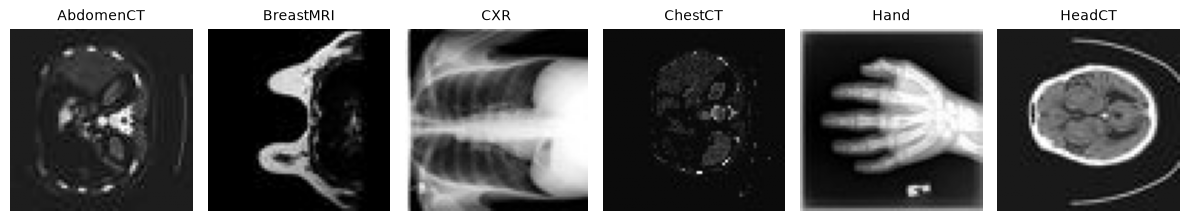

In [6]:
from monai.transforms import LoadImage

loader = LoadImage(image_only=True)
fig, axes = plt.subplots(1, num_classes, figsize=(2.0 * num_classes, 2.4))
for label, cname in enumerate(class_names):
    idx = int(np.where(image_labels == label)[0][0])
    axes[label].imshow(np.asarray(loader(image_files[idx])), cmap="gray")
    axes[label].set_title(cname, fontsize=10)
    axes[label].axis("off")
plt.tight_layout(); plt.show()

## 3 · Preprocessing as explicit steps (MONAI transforms)

A MONAI transform pipeline is just a list of steps applied to every image. Keeping them explicit is the point — this is exactly the vocabulary you'll reuse on pathology next week, where the steps matter far more.

- **`LoadImage`** — read the file into an array.
- **`EnsureChannelFirst`** — add the channel axis → shape `(1, 64, 64)`, the layout a CNN expects.
- **`ScaleIntensity`** — rescale pixel values to `[0, 1]` so training is stable.
- **`EnsureType`** — hand back a plain PyTorch tensor.

We deliberately skip random augmentation in this toy so behaviour stays predictable (and so the planted marker later can't get flipped away).

In [7]:
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, EnsureType

transforms = Compose([
    LoadImage(image_only=True),
    EnsureChannelFirst(),
    ScaleIntensity(),
    EnsureType(track_meta=False),
])

# Sanity-check the output shape and range on one image.
sample = transforms(image_files[0])
print("shape:", tuple(sample.shape), "| min:", float(sample.min()), "| max:", float(sample.max()))

shape: (1, 64, 64) | min: 0.0 | max: 1.0


## 4 · Train / validation / test split, and a Dataset

We shuffle, carve out validation and test sets, and — to keep this a *toy* that finishes on a laptop — subsample: 1,000 training images per class, 2,000 for validation, 2,000 for test. (Raise the numbers to use more data; it just takes longer.)

The `Dataset` class simply pairs `transforms(image_path)` with its label — nothing hidden. One convenience: each image is preprocessed **once** and kept in memory, so later epochs don't re-read the disk. The first epoch is the slowest for that reason.

In [8]:
from torch.utils.data import Dataset, DataLoader

TRAIN_PER_CLASS = 1000   # subset for speed; set to None for the full training set
N_VAL, N_TEST = 2000, 2000

rng = np.random.default_rng(SEED)
perm = rng.permutation(len(image_files))

test_idx = perm[:N_TEST]
val_idx = perm[N_TEST:N_TEST + N_VAL]
train_idx = perm[N_TEST + N_VAL:]

# Subsample the training indices evenly per class.
if TRAIN_PER_CLASS is not None:
    keep = []
    for label in range(num_classes):
        cls = train_idx[image_labels[train_idx] == label]
        keep.append(cls[:TRAIN_PER_CLASS])
    train_idx = rng.permutation(np.concatenate(keep))

print(f"train: {len(train_idx)} | val: {len(val_idx)} | test: {len(test_idx)}")

_cache = {}
def load_image(j):
    """Run the transform pipeline on image j once, then reuse the result."""
    if j not in _cache:
        _cache[j] = transforms(image_files[j])
    return _cache[j]

class MedNISTDataset(Dataset):
    def __init__(self, indices, mark_label=None):
        # mark_label is used later for the confounder demo; None here.
        self.indices = list(indices)
        self.mark_label = mark_label
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]
        img = load_image(j)
        label = int(image_labels[j])
        if self.mark_label is not None and label == self.mark_label:
            img = stamp_marker(img)          # defined in the confounder section
        return img, label

train_ds = MedNISTDataset(train_idx)
val_ds   = MedNISTDataset(val_idx)
test_ds  = MedNISTDataset(test_idx)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=256)
test_loader  = DataLoader(test_ds,  batch_size=256)

train: 6000 | val: 2000 | test: 2000


## 5 · A tiny CNN — built so you can see the hierarchy

This is a deliberately small network, written by hand rather than imported, so the structure from the lecture is visible: three convolution blocks stacked, each followed by pooling that **zooms out** and widens what the next layer sees — edges, then textures, then structures.

At the end, **global max pooling** collapses each of the 64 feature maps to a single number: *"did this feature fire strongly **anywhere** in the image?"* That is a good fit for recognising anatomy — and, as you'll see in Section 9, it also means one small, bright, consistent patch anywhere in the image can be enough to swing a decision. Remember that.

We name the feature extractor `features` so Grad-CAM can point at its last convolution block later.

In [9]:
class TinyCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),   # 64 -> 32
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32 -> 16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16 -> 8
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveMaxPool2d(1), nn.Flatten(), nn.Linear(64, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

# Grad-CAM reads the last conv block's activations: the ReLU after the last convolution
# (index 7 in `features`), i.e. the 8x8 map of "which feature fired where".
TARGET_LAYER = "features.7"

model = TinyCNN(num_classes).to(device)
print(model)
print("trainable parameters:", sum(p.numel() for p in model.parameters()))

TinyCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveMaxPool2d(output_size=1)
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=64, out_features=6, bias=True)
  )
)
trainable parameters: 23686


## 6 · Train from scratch — and watch it work

No pretrained weights. We train the whole thing from random initialisation. Because MedNIST is large and easy, a tiny CNN climbs into the high-90s within a handful of epochs. Watch the loss fall and the validation accuracy rise.

In [10]:
def run_epoch(net, loader, optimizer=None):
    train_mode = optimizer is not None
    net.train() if train_mode else net.eval()
    total, correct, loss_sum = 0, 0, 0.0
    criterion = nn.CrossEntropyLoss()
    with torch.set_grad_enabled(train_mode):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            logits = net(imgs)
            loss = criterion(logits, labels)
            if train_mode:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item() * imgs.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += imgs.size(0)
    return loss_sum / total, correct / total

def train(net, train_loader, val_loader, epochs, lr=1e-3):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(net, train_loader, opt)
        va_loss, va_acc = run_epoch(net, val_loader)
        print(f"epoch {ep}:  train loss {tr_loss:.3f} acc {tr_acc:.3f}  |  "
              f"val loss {va_loss:.3f} acc {va_acc:.3f}")
    return net

EPOCHS = 8
train(model, train_loader, val_loader, epochs=EPOCHS)

epoch 1:  train loss 1.304 acc 0.603  |  val loss 0.551 acc 0.876
epoch 2:  train loss 0.321 acc 0.930  |  val loss 0.160 acc 0.965
epoch 3:  train loss 0.132 acc 0.962  |  val loss 0.085 acc 0.976
epoch 4:  train loss 0.072 acc 0.981  |  val loss 0.068 acc 0.979
epoch 5:  train loss 0.055 acc 0.985  |  val loss 0.054 acc 0.986
epoch 6:  train loss 0.042 acc 0.989  |  val loss 0.050 acc 0.985
epoch 7:  train loss 0.034 acc 0.991  |  val loss 0.041 acc 0.985
epoch 8:  train loss 0.031 acc 0.991  |  val loss 0.035 acc 0.988


TinyCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveMaxPool2d(output_size=1)
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=64, out_features=6, bias=True)
  )
)

## 7 · Evaluate — accuracy and a confusion matrix

Where does it still confuse classes? The confusion matrix shows it per class.

test accuracy: 0.9925


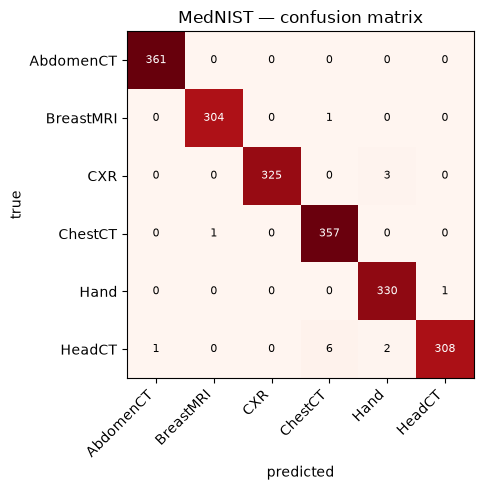

In [11]:
from sklearn.metrics import confusion_matrix

def collect_preds(net, loader):
    net.eval()
    ys, ps = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            logits = net(imgs.to(device))
            ps.append(logits.argmax(1).cpu().numpy())
            ys.append(labels.numpy())
    return np.concatenate(ys), np.concatenate(ps)

def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(num_classes))
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.imshow(cm, cmap="Reds")
    ax.set_xticks(range(num_classes)); ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticks(range(num_classes)); ax.set_yticklabels(class_names)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for i in range(num_classes):
        for j in range(num_classes):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
    plt.title(title); plt.tight_layout(); plt.show()

y_true, y_pred = collect_preds(model, test_loader)
print(f"test accuracy: {(y_true == y_pred).mean():.4f}")
plot_confusion(y_true, y_pred, "MedNIST — confusion matrix")

> **Read it:** scratch training *worked* — high accuracy, a clean diagonal. Hold on to *why*: the data was easy and there was a lot of it. That is the setup for next week's contrast.

## 8 · Grad-CAM: where did the model look?

Accuracy says the model is right. It says nothing about *why*. **Grad-CAM** produces a heatmap over the image showing which regions drove the prediction — the one tool this module is built around.

Here, on clean MedNIST, the right answer is obvious: the heat should sit on the **anatomy**. That's the point of trying it here first — you can tell at a glance whether it's behaving, before pathology makes the judgement hard.

> 🔧 **A real-world gotcha, fixed in the code below.** MONAI's `GradCAM` by default rescales its map so that the *most* important pixels come out as **0** and the least important as **1** (its documentation says it "will flip magnitudes"). Plot that with a colormap and you get the exact opposite of the truth — red background, cool anatomy — and you'd draw the wrong conclusion. We pass our own `postprocessing` that keeps **high = important**. Lesson: sanity-check your explanation tool on a case where you already know the answer — which is precisely why we start on easy data.

Colour key (jet): **red = drove the prediction**, **blue = ignored**.

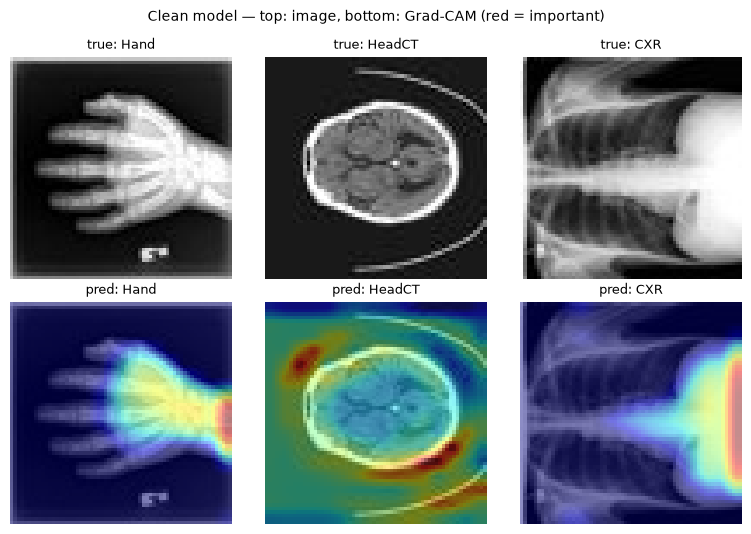

In [12]:
from monai.visualize import GradCAM

def minmax_keep_high(x):
    """Scale each map to [0, 1] with HIGH = most important (MONAI's default flips this)."""
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    hi = flat.max(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    return (x - lo) / (hi - lo + 1e-8)

def make_cam(net):
    return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

def gradcam_panel(net, cam_obj, img, ax_img, ax_cam, top_title):
    """img: tensor (1, 64, 64). Draws the image and its Grad-CAM overlay; returns the prediction."""
    net.eval()
    x = img.unsqueeze(0).to(device)                                  # (1,1,64,64)
    pred = int(net(x).argmax(1).item())
    heat = cam_obj(x=x, class_idx=pred).squeeze().detach().cpu().numpy()   # 64x64, 0..1
    base = img.squeeze().cpu().numpy()
    ax_img.imshow(base, cmap="gray"); ax_img.set_title(top_title, fontsize=9)
    ax_cam.imshow(base, cmap="gray")
    ax_cam.imshow(heat, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax_cam.set_title(f"pred: {class_names[pred]}", fontsize=9)
    ax_img.axis("off"); ax_cam.axis("off")
    return pred

cam = make_cam(model)

# One example each from Hand, HeadCT and CXR — anatomy you can eyeball.
examples = {c: int(np.where(image_labels == class_names.index(c))[0][0])
            for c in ["Hand", "HeadCT", "CXR"]}

fig, axes = plt.subplots(2, 3, figsize=(7.8, 5.4))
for col, (cname, j) in enumerate(examples.items()):
    gradcam_panel(model, cam, load_image(j), axes[0, col], axes[1, col], f"true: {cname}")
fig.suptitle("Clean model — top: image, bottom: Grad-CAM (red = important)", fontsize=10)
plt.tight_layout(); plt.show()

The heat lands on the anatomy — the hand and wrist, the skull, the chest. Good: this model earned its predictions. Now we break one on purpose.

## 9 · Clever Hans: a planted shortcut

From the lecture: a model can be **right for the wrong reason**. Real cases (dermatology models keying on rulers, chest-X-ray models keying on scanner tags) are subtle. Here we make the shortcut *obvious and controlled* so you can see the mechanism with ground truth you planted yourself.

**The experiment:** stamp a small white square in the top-left corner of **every `Hand` image** — in training *and* validation, just as a hospital-specific tag would appear in all of a hospital's data. The square is now a perfect giveaway for the `Hand` label, and far easier to learn than hand anatomy. A lazy model will take the bait.

> ⚠️ **The marker is 100% synthetic.** It is not in the real data and has no biological meaning. We are manufacturing a confounder to study it.

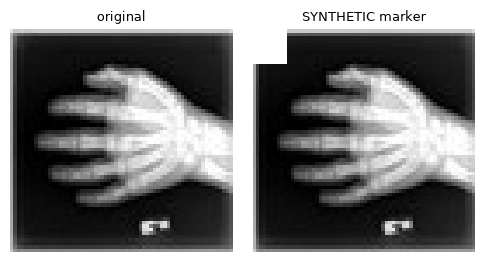

In [13]:
MARK_CLASS = class_names.index("Hand")
MARK_SIZE = 10   # pixels

def stamp_marker(img):
    # img: tensor (1, 64, 64), intensity-scaled to [0,1]. Paint a white corner square.
    out = img.clone()
    out[:, :MARK_SIZE, :MARK_SIZE] = 1.0
    return out

# Show the marker on one Hand image (clearly synthetic).
clean = load_image(examples["Hand"])
marked = stamp_marker(clean)
fig, ax = plt.subplots(1, 2, figsize=(5, 2.6))
ax[0].imshow(clean.squeeze().cpu().numpy(), cmap="gray"); ax[0].set_title("original", fontsize=9)
ax[1].imshow(marked.squeeze().cpu().numpy(), cmap="gray"); ax[1].set_title("SYNTHETIC marker", fontsize=9)
ax[0].axis("off"); ax[1].axis("off"); plt.tight_layout(); plt.show()

In [15]:
# Retrain an identical tiny CNN where every Hand image (train AND validation) carries the marker.
set_determinism(seed=SEED)
marked_train_loader = DataLoader(MedNISTDataset(train_idx, mark_label=MARK_CLASS), batch_size=128, shuffle=True)
marked_val_loader   = DataLoader(MedNISTDataset(val_idx,   mark_label=MARK_CLASS), batch_size=256)

model_cf = TinyCNN(num_classes).to(device)
train(model_cf, marked_train_loader, marked_val_loader, epochs=EPOCHS)

epoch 1:  train loss 1.258 acc 0.597  |  val loss 0.478 acc 0.884
epoch 2:  train loss 0.287 acc 0.936  |  val loss 0.136 acc 0.972
epoch 3:  train loss 0.113 acc 0.969  |  val loss 0.071 acc 0.983
epoch 4:  train loss 0.061 acc 0.987  |  val loss 0.055 acc 0.987
epoch 5:  train loss 0.042 acc 0.990  |  val loss 0.034 acc 0.991
epoch 6:  train loss 0.030 acc 0.993  |  val loss 0.028 acc 0.991
epoch 7:  train loss 0.022 acc 0.994  |  val loss 0.023 acc 0.992
epoch 8:  train loss 0.019 acc 0.995  |  val loss 0.019 acc 0.992


TinyCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveMaxPool2d(output_size=1)
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=64, out_features=6, bias=True)
  )
)

Look at that validation accuracy: just as high as the clean model's. **If this were all you checked, you would ship this model.** Let's see what it actually learned.

## 10 · Catch it

Three tells that the model learned the square, not the hand:

1. **Take the marker away** and its `Hand` performance collapses.
2. **Grad-CAM on a marked Hand image lights the corner**, not the anatomy.
3. **Stamp the marker onto a *non-Hand* image** and the model flips its prediction to `Hand` — the shortcut, exposed.

overall accuracy  — marked test: 0.994   clean test: 0.829
Hand recall       — marked test: 1.000   clean test: 0.000


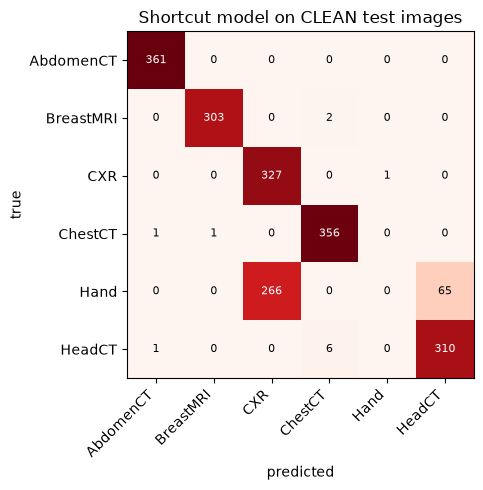

In [16]:
# Tell 1: same test images, with and without the marker.
marked_test_loader = DataLoader(MedNISTDataset(test_idx, mark_label=MARK_CLASS), batch_size=256)
y_m, p_m = collect_preds(model_cf, marked_test_loader)   # the world it was trained in
y_c, p_c = collect_preds(model_cf, test_loader)          # the real world: no marker

hand = y_c == MARK_CLASS
print(f"overall accuracy  — marked test: {(y_m == p_m).mean():.3f}   clean test: {(y_c == p_c).mean():.3f}")
print(f"Hand recall       — marked test: {(p_m[hand] == MARK_CLASS).mean():.3f}   clean test: {(p_c[hand] == MARK_CLASS).mean():.3f}")
plot_confusion(y_c, p_c, "Shortcut model on CLEAN test images")

Without the square, the model can barely recognise a hand — look at the `Hand` row of the confusion matrix. Overall accuracy only drops by about one sixth, because the other five classes are fine: a single headline number hides a failure that is total for one class.

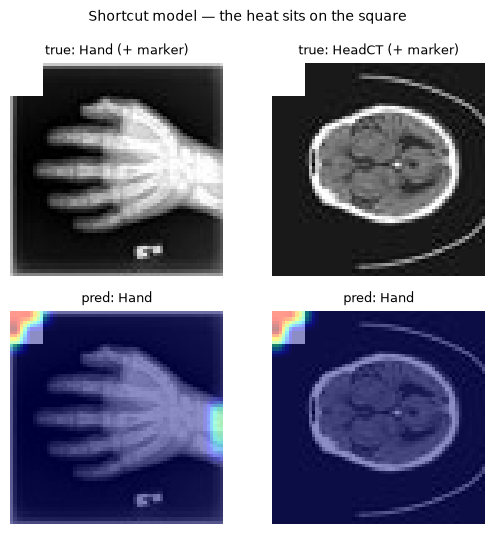

prediction on a MARKED HeadCT image: Hand <- the shortcut wins


In [17]:
# Tells 2 and 3: Grad-CAM on a marked Hand image, and on a HeadCT with the marker stamped on.
cam_cf = make_cam(model_cf)

fig, axes = plt.subplots(2, 2, figsize=(5.4, 5.4))
gradcam_panel(model_cf, cam_cf, stamp_marker(load_image(examples["Hand"])),
              axes[0, 0], axes[1, 0], "true: Hand (+ marker)")
pred = gradcam_panel(model_cf, cam_cf, stamp_marker(load_image(examples["HeadCT"])),
                     axes[0, 1], axes[1, 1], "true: HeadCT (+ marker)")
fig.suptitle("Shortcut model — the heat sits on the square", fontsize=10)
plt.tight_layout(); plt.show()
print("prediction on a MARKED HeadCT image:", class_names[pred],
      "<- the shortcut wins" if pred == MARK_CLASS else "")

In [18]:
# One image could be luck. Stamp the marker on EVERY non-Hand test image and count the flips.
# Control: the clean model sees the same stamped images.
nonhand = [j for j in test_idx if image_labels[j] != MARK_CLASS]

def flip_rate(net):
    net.eval(); flipped = 0
    with torch.no_grad():
        for k in range(0, len(nonhand), 256):
            batch = torch.stack([stamp_marker(load_image(j)) for j in nonhand[k:k + 256]]).to(device)
            flipped += (net(batch).argmax(1) == MARK_CLASS).sum().item()
    return flipped / len(nonhand)

print(f"non-Hand images stamped with the marker: {len(nonhand)}")
print(f"  predicted 'Hand' by the CLEAN model    : {flip_rate(model):.1%}")
print(f"  predicted 'Hand' by the SHORTCUT model : {flip_rate(model_cf):.1%}")

non-Hand images stamped with the marker: 1669
  predicted 'Hand' by the CLEAN model    : 31.5%
  predicted 'Hand' by the SHORTCUT model : 97.7%


Read the two numbers together:

- The **shortcut model** calls almost *every* image carrying the square a hand. That is the planted confounder, caught red-handed.
- Even the **clean model** is rattled by a fair fraction of them — it never saw a white square in training, and a bright artifact it has never seen can push it around too. That is a second, separate lesson: models are unreliable on inputs unlike anything in their training data (*out-of-distribution* inputs), which is exactly what a new scanner or a new hospital's data looks like.

Same architecture, same images, near-identical validation accuracy — the difference in how hard they fall for the square is what each one learned to look at.

## What you just saw, and where it goes

- You ran the **whole MONAI pipeline** end to end — load, preprocess, train, evaluate — with nothing hidden.
- Training **from scratch succeeded**, because MedNIST is easy and plentiful.
- **Grad-CAM** answered *"where did it look?"* — on clean data where the answer was obvious, then on a model you **broke on purpose**, where it exposed a planted shortcut that validation accuracy completely hid.
- And you met a small but very real hazard: an explanation tool whose default output was **upside down**. Always check your tools on a case where you know the answer.

**The hand-forward to next week.** The real-data notebook changes both things that made this easy: pathology tiles are **few** and **messy**. Scratch training overfits, so you'll fine-tune a pretrained **DenseNet121** (transfer learning) — and the confounder stops being a white square you planted and becomes a **naturally occurring** stain blob or slide-edge artifact you have to go find. The graded notebook then asks you to hunt for your own.

> Toy → engineered and obvious.  Real → subtle and real.  Graded → find it yourself.

Finish with `Kernel → Restart & Run All` and confirm the whole notebook runs clean, top to bottom.